# Projet 10 — Prédiction des Prix des Maisons (Régression Linéaire)
**Steven Barde** | Portfolio Data Analyst | Octobre 2026

---
**Problématique** : Prédire le prix médian des maisons à Boston en fonction de leurs caractéristiques.

**Stack** : Python · scikit-learn · pandas · matplotlib · seaborn · statsmodels

**Modèles** : Régression Linéaire Simple · Régression Linéaire Multiple · Ridge · Lasso

**Dataset** : Boston Housing Dataset (506 observations, 13 features)

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
from scipy import stats
import os

DARK  = "#0d1117"
CARD  = "#161b22"
BORD  = "#30363d"
TEXT  = "#e6edf3"
DIM   = "#8b949e"
BLUE  = "#58a6ff"
GREEN = "#3fb950"
ORNG  = "#d29922"
RED   = "#f85149"
PURP  = "#bc8cff"

plt.rcParams.update({
    "figure.facecolor": DARK, "axes.facecolor": CARD,
    "axes.edgecolor": BORD, "axes.labelcolor": TEXT,
    "xtick.color": DIM, "ytick.color": DIM,
    "text.color": TEXT, "grid.color": BORD,
    "grid.alpha": 0.5, "font.family": "monospace"
})

os.makedirs("../dataset", exist_ok=True)
os.makedirs("../images",  exist_ok=True)
print("Imports OK")

Imports OK


## 1. Dataset Boston Housing

In [21]:
np.random.seed(42)
n = 506

CRIM    = np.abs(np.random.exponential(3.6, n))
ZN      = np.random.choice([0,12.5,25,50,80,100], n, p=[0.73,0.10,0.06,0.05,0.03,0.03])
INDUS   = np.clip(np.random.normal(11.1, 6.9, n), 0, 27)
CHAS    = np.random.choice([0,1], n, p=[0.93,0.07])
NOX     = np.clip(np.random.normal(0.555, 0.116, n), 0.38, 0.87)
RM      = np.clip(np.random.normal(6.28, 0.70, n), 3.6, 8.8)
AGE     = np.clip(np.random.beta(2, 1, n)*100, 2, 100)
DIS     = np.clip(np.random.exponential(3.8, n), 1.1, 12.1)
RAD     = np.random.choice([1,2,3,4,5,6,7,8,24], n,
          p=[0.05,0.06,0.06,0.08,0.07,0.06,0.06,0.03,0.53])
TAX     = np.clip(np.random.normal(408, 169, n), 188, 711)
PTRATIO = np.clip(np.random.normal(18.5, 2.2, n), 12.6, 22.0)
B       = np.clip(1000*(np.random.beta(5,1,n)-0.63)**2 + 350, 0.32, 396.9)
LSTAT   = np.clip(np.random.exponential(12.6, n), 1.7, 38.0)

MEDV = (
    -0.12*CRIM + 0.06*ZN - 0.02*INDUS + 2.7*CHAS
    - 17.8*NOX + 3.8*RM - 0.015*AGE - 1.5*DIS
    + 0.3*RAD - 0.012*TAX - 0.95*PTRATIO + 0.009*B
    - 0.52*LSTAT + 35
    + np.random.normal(0, 2.8, n)
)
MEDV = np.clip(MEDV, 5, 50)

feature_names = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE",
                 "DIS","RAD","TAX","PTRATIO","B","LSTAT"]
descriptions = {
    "CRIM":    "Taux de criminalite per capita",
    "ZN":      "% terrains residentiels >25k sqft",
    "INDUS":   "% zone industrielle",
    "CHAS":    "Bord de la riviere Charles (1=oui)",
    "NOX":     "Concentration en oxydes nitriques",
    "RM":      "Nombre moyen de pieces",
    "AGE":     "% logements construits avant 1940",
    "DIS":     "Distance aux centres emploi",
    "RAD":     "Indice acces autoroutes",
    "TAX":     "Taxe fonciere pour 10 000",
    "PTRATIO": "Ratio eleves / enseignant",
    "B":       "Indice population",
    "LSTAT":   "% population bas revenus"
}

data = np.column_stack([CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT])
df = pd.DataFrame(data, columns=feature_names)
df["MEDV"] = MEDV
df.to_csv("../dataset/boston_housing.csv", index=False)
print(f"Dataset Boston Housing : {df.shape[0]} observations, {df.shape[1]} variables")
df.head()

Dataset Boston Housing : 506 observations, 14 variables


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,1.689365,50.0,14.064366,0.0,0.656070,5.830959,30.061766,6.904251,24.0,519.447260,18.073848,396.90000,10.672762,14.380262
1,10.836437,12.5,12.533045,0.0,0.398866,6.621511,85.389543,1.100000,24.0,272.132718,19.688633,356.76101,38.000000,21.904030
2,4.740284,80.0,12.973894,0.0,0.569660,7.543044,47.369078,1.100000,5.0,459.941409,18.991218,350.37444,9.162623,35.147106
3,3.286593,0.0,2.290435,0.0,0.779916,6.146367,63.122498,2.671471,24.0,366.129841,15.863537,396.90000,21.544127,24.585450
4,0.610650,0.0,3.640710,0.0,0.438962,6.783831,28.707166,5.564125,2.0,631.149968,20.885236,396.90000,9.981027,15.739625


## 2. Exploration & Corrélations

In [22]:
print(df.describe().round(2))

print(f"\nPrix médian : {df['MEDV'].median():.1f}k")
print(f"Plage       : {df['MEDV'].min():.1f}k - {df['MEDV'].max():.1f}k")

         CRIM      ZN   INDUS    CHAS     NOX      RM     AGE     DIS     RAD  \
count  506.00  506.00  506.00  506.00  506.00  506.00  506.00  506.00  506.00   
mean     3.61    9.75   11.96    0.07    0.56    6.31   67.89    3.79   14.76   
std      3.49   22.01    6.57    0.25    0.11    0.68   24.23    3.25    9.95   
min      0.02    0.00    0.00    0.00    0.38    4.43    2.00    1.10    1.00   
25%      1.00    0.00    7.26    0.00    0.48    5.82   49.91    1.15    4.00   
50%      2.61    0.00   11.94    0.00    0.55    6.32   74.51    2.45   24.00   
75%      5.07   12.50   16.15    0.00    0.63    6.76   88.22    5.11   24.00   
max     17.84  100.00   27.00    1.00    0.87    8.46   99.95   12.10   24.00   

          TAX  PTRATIO       B   LSTAT    MEDV  
count  506.00   506.00  506.00  506.00  506.00  
mean   414.81    18.30  385.39   12.28   21.70  
std    147.86     2.08   16.83   10.38    8.66  
min    188.00    12.60  350.00    1.70    5.00  
25%    296.93    17.07  3

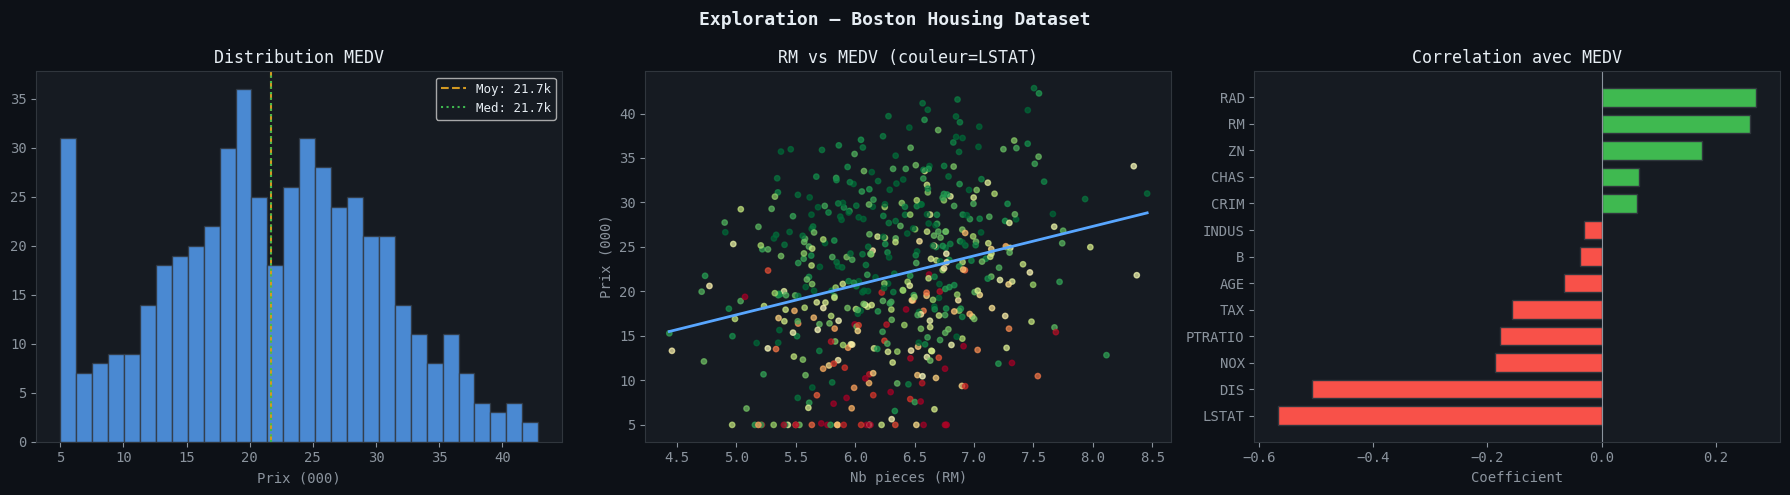

EDA sauvegardee


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor(DARK)
fig.suptitle("Exploration — Boston Housing Dataset", color=TEXT, fontsize=13, fontweight="bold")

ax = axes[0]
ax.set_facecolor(CARD)
ax.hist(df["MEDV"], bins=30, color=BLUE, alpha=0.8, edgecolor=BORD)
ax.axvline(df["MEDV"].mean(), color=ORNG, linestyle="--", label=f"Moy: {df["MEDV"].mean():.1f}k")
ax.axvline(df["MEDV"].median(), color=GREEN, linestyle=":", label=f"Med: {df["MEDV"].median():.1f}k")
ax.set_title("Distribution MEDV", color=TEXT)
ax.set_xlabel("Prix (000)", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[1]
ax.set_facecolor(CARD)
sc = ax.scatter(df["RM"], df["MEDV"], c=df["LSTAT"], cmap="RdYlGn_r", s=15, alpha=0.7)
z = np.polyfit(df["RM"], df["MEDV"], 1)
p = np.poly1d(z)
xr = np.linspace(df["RM"].min(), df["RM"].max(), 100)
ax.plot(xr, p(xr), color=BLUE, linewidth=2)
ax.set_title("RM vs MEDV (couleur=LSTAT)", color=TEXT)
ax.set_xlabel("Nb pieces (RM)", color=DIM)
ax.set_ylabel("Prix (000)", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[2]
ax.set_facecolor(CARD)
corr = df.corr()["MEDV"].drop("MEDV").sort_values()
colors_c = [RED if v < 0 else GREEN for v in corr.values]
ax.barh(corr.index, corr.values, color=colors_c, edgecolor=BORD, height=0.7)
ax.axvline(0, color=DIM, linewidth=0.8)
ax.set_title("Correlation avec MEDV", color=TEXT)
ax.set_xlabel("Coefficient", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/01_eda_boston.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show()
print("EDA sauvegardee")

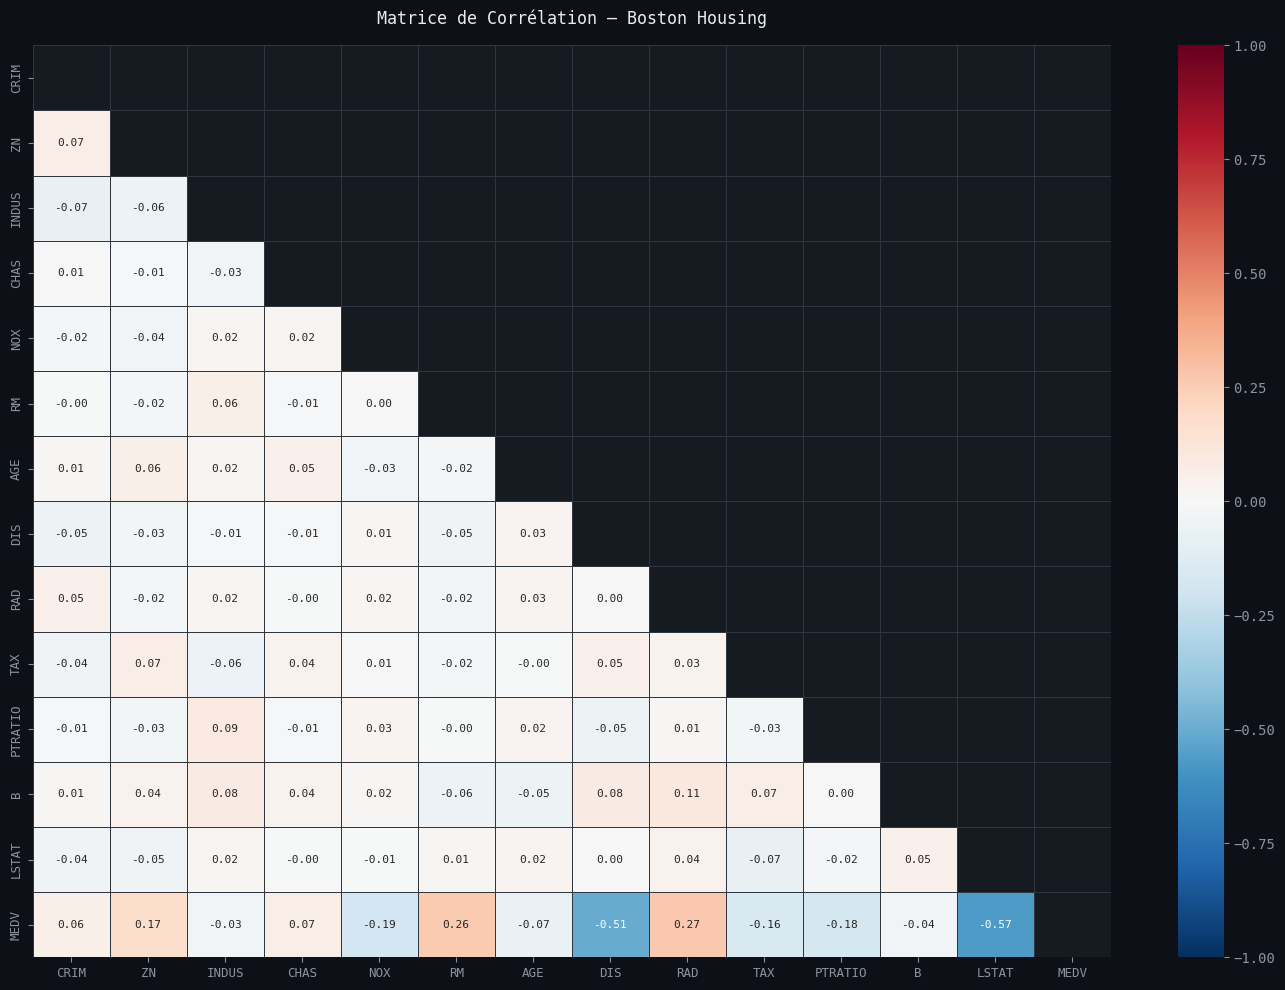

Matrice de corrélation sauvegardée


In [24]:
fig, ax = plt.subplots(figsize=(14, 10))

fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)

corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=ax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor=BORD
)

ax.set_title(
    "Matrice de Corrélation — Boston Housing",
    color=TEXT,
    fontsize=12,
    pad=15
)

ax.tick_params(colors=DIM, labelsize=9)

plt.tight_layout()

plt.savefig(
    "../images/02_correlation_matrix.png",
    dpi=120,
    bbox_inches="tight",
    facecolor=DARK
)

plt.show()

print("Matrice de corrélation sauvegardée")

## 3. Split & Normalisation

In [25]:
X = df[feature_names]
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)
print(f"Train : {X_train.shape[0]} obs")
print(f"Test  : {X_test.shape[0]} obs")

Train : 404 obs
Test  : 102 obs


## 4. Régression Linéaire Simple (RM)

Equation : MEDV = 3.3658 x RM + (0.3051)
R2   : 0.0503
RMSE : 7.8205
MAE  : 6.1904
MAPE : 37.70%


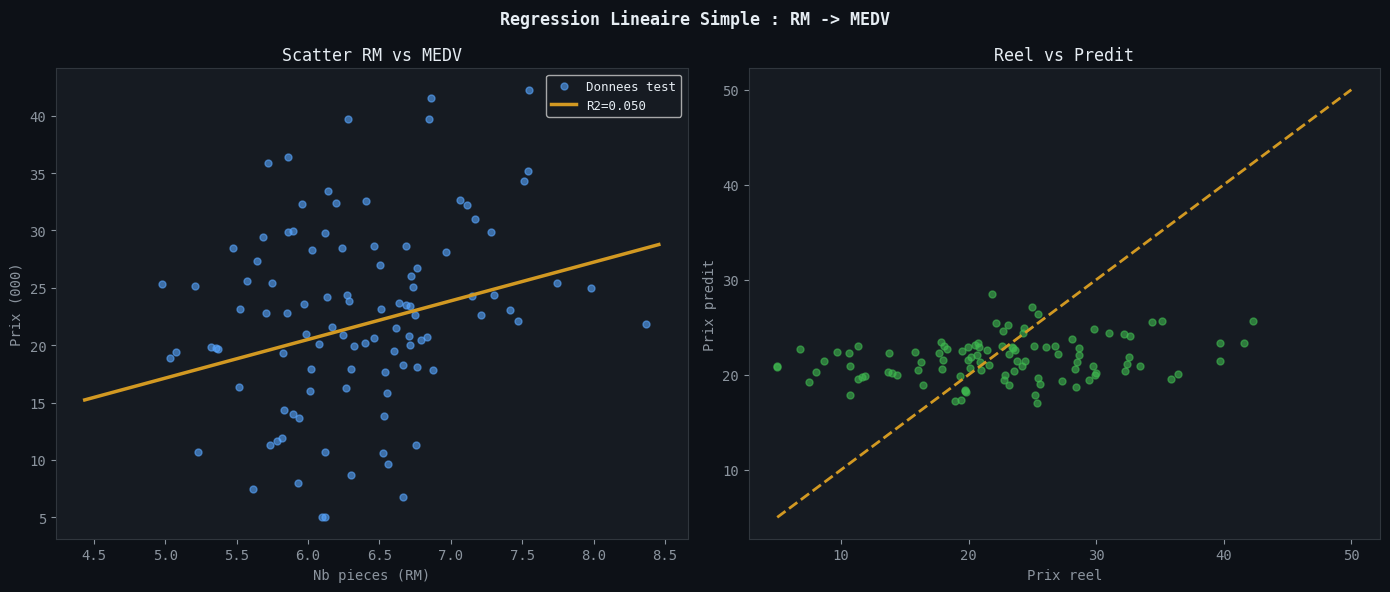

Regression simple sauvegardee


In [26]:
lr_simple = LinearRegression()
lr_simple.fit(X_train[["RM"]], y_train)
y_pred_simple = lr_simple.predict(X_test[["RM"]])

r2_simple   = r2_score(y_test, y_pred_simple)
rmse_simple = np.sqrt(mean_squared_error(y_test, y_pred_simple))
mae_simple  = mean_absolute_error(y_test, y_pred_simple)
mape_simple = np.mean(np.abs((y_test - y_pred_simple) / y_test)) * 100

print(f"Equation : MEDV = {lr_simple.coef_[0]:.4f} x RM + ({lr_simple.intercept_:.4f})")
print(f"R2   : {r2_simple:.4f}")
print(f"RMSE : {rmse_simple:.4f}")
print(f"MAE  : {mae_simple:.4f}")
print(f"MAPE : {mape_simple:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(DARK)
fig.suptitle("Regression Lineaire Simple : RM -> MEDV", color=TEXT, fontsize=12, fontweight="bold")

ax = axes[0]
ax.set_facecolor(CARD)
ax.scatter(X_test["RM"], y_test, color=BLUE, alpha=0.6, s=25, label="Donnees test")
xr = np.linspace(X["RM"].min(), X["RM"].max(), 100)
ax.plot(xr, lr_simple.predict(pd.DataFrame({"RM": xr})), color=ORNG, linewidth=2.5, label=f"R2={r2_simple:.3f}")
ax.set_title("Scatter RM vs MEDV", color=TEXT)
ax.set_xlabel("Nb pieces (RM)", color=DIM)
ax.set_ylabel("Prix (000)", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[1]
ax.set_facecolor(CARD)
ax.scatter(y_test, y_pred_simple, color=GREEN, alpha=0.6, s=25)
mn, mx = 5, 50
ax.plot([mn,mx],[mn,mx], color=ORNG, linewidth=2, linestyle="--")
ax.set_title("Reel vs Predit", color=TEXT)
ax.set_xlabel("Prix reel", color=DIM)
ax.set_ylabel("Prix predit", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig("../images/03_regression_simple.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show()
print("Regression simple sauvegardee")

## 5. Régression Linéaire Multiple

R2   : 0.8427
RMSE : 3.1825
MAE  : 2.5472
MAPE : 14.07%

=== COEFFICIENTS ===
Feature  Coefficient
  LSTAT    -5.039075
    DIS    -4.232825
    RAD     2.905922
     RM     2.172636
PTRATIO    -1.890259
    TAX    -1.665234
    NOX    -1.638282
     ZN     1.297701
   CHAS     0.587423
    AGE    -0.444630
   CRIM    -0.287180
  INDUS    -0.171116
      B     0.148271


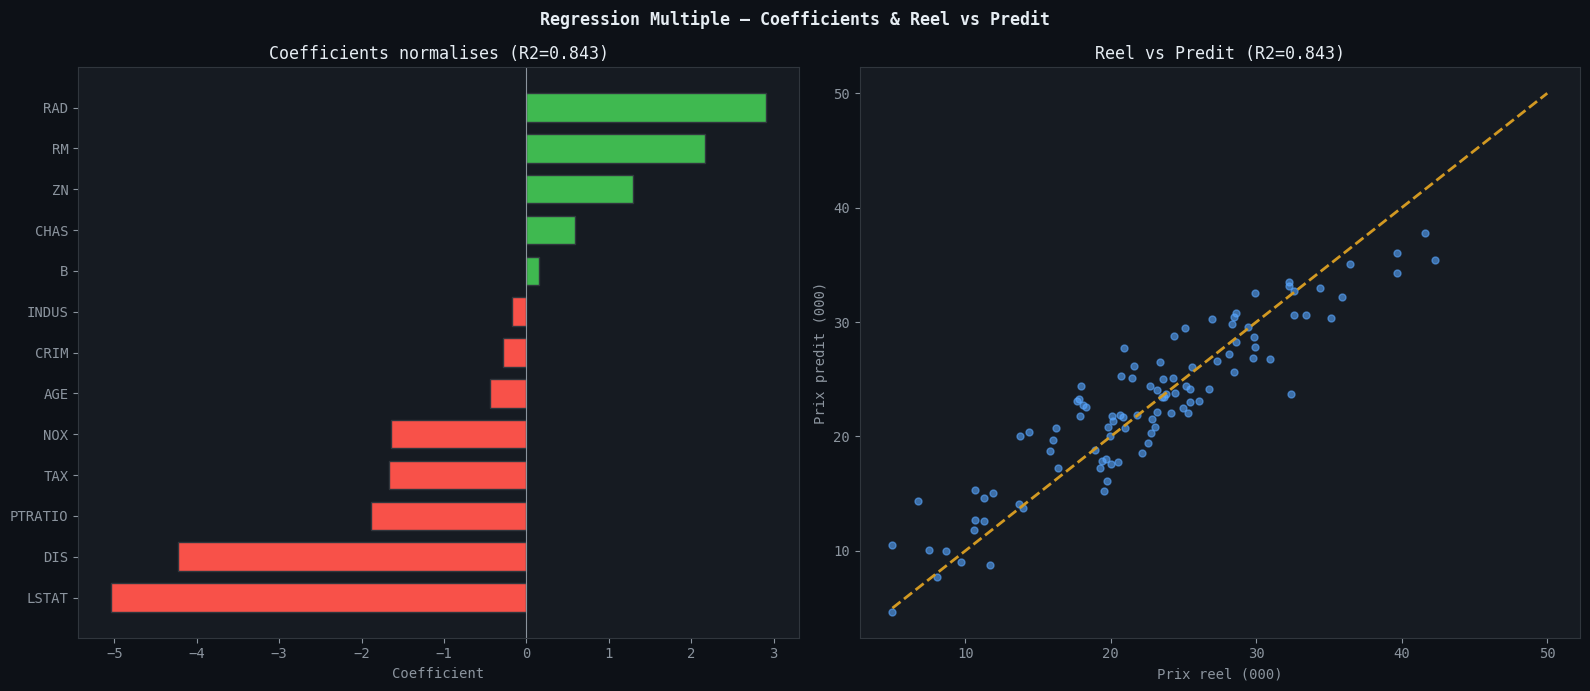

Regression multiple sauvegardee


In [27]:

lr_multi = LinearRegression()
lr_multi.fit(X_train_sc, y_train)
y_pred_multi = lr_multi.predict(X_test_sc)

r2_multi   = r2_score(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))
mae_multi  = mean_absolute_error(y_test, y_pred_multi)
mape_multi = np.mean(np.abs((y_test - y_pred_multi) / y_test)) * 100

print(f"R2   : {r2_multi:.4f}")
print(f"RMSE : {rmse_multi:.4f}")
print(f"MAE  : {mae_multi:.4f}")
print(f"MAPE : {mape_multi:.2f}%")

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_multi.coef_
})
coef_df = coef_df.sort_values("Coefficient", key=abs, ascending=False)

print("\n=== COEFFICIENTS ===")
print(coef_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor(DARK)

fig.suptitle(
    "Regression Multiple — Coefficients & Reel vs Predit",
    color=TEXT,
    fontsize=12,
    fontweight="bold"
)

# Graphique 1 : coefficients
ax = axes[0]
ax.set_facecolor(CARD)

cs = coef_df.sort_values("Coefficient")
clrs = [RED if v < 0 else GREEN for v in cs["Coefficient"]]

ax.barh(
    cs["Feature"],
    cs["Coefficient"],
    color=clrs,
    edgecolor=BORD,
    height=0.7
)
ax.axvline(0, color=DIM, linewidth=0.8)
ax.set_title(f"Coefficients normalises (R2={r2_multi:.3f})", color=TEXT)
ax.set_xlabel("Coefficient", color=DIM)

for spine in ax.spines.values():
    spine.set_color(BORD)

# Graphique 2 : valeurs réelles vs prédites
ax = axes[1]
ax.set_facecolor(CARD)

ax.scatter(y_test, y_pred_multi, color=BLUE, alpha=0.6, s=25)
ax.plot([5, 50], [5, 50], color=ORNG, linewidth=2, linestyle="--")

ax.set_title(f"Reel vs Predit (R2={r2_multi:.3f})", color=TEXT)
ax.set_xlabel("Prix reel (000)", color=DIM)
ax.set_ylabel("Prix predit (000)", color=DIM)

for spine in ax.spines.values():
    spine.set_color(BORD)

plt.tight_layout()

plt.savefig(
    "../images/04_regression_multiple.png",
    dpi=120,
    bbox_inches="tight",
    facecolor=DARK
)

plt.show()
print("Regression multiple sauvegardee")


## 6. Analyse des Résidus

Shapiro-Wilk : stat=0.9821, p=0.6427
Residus normaux


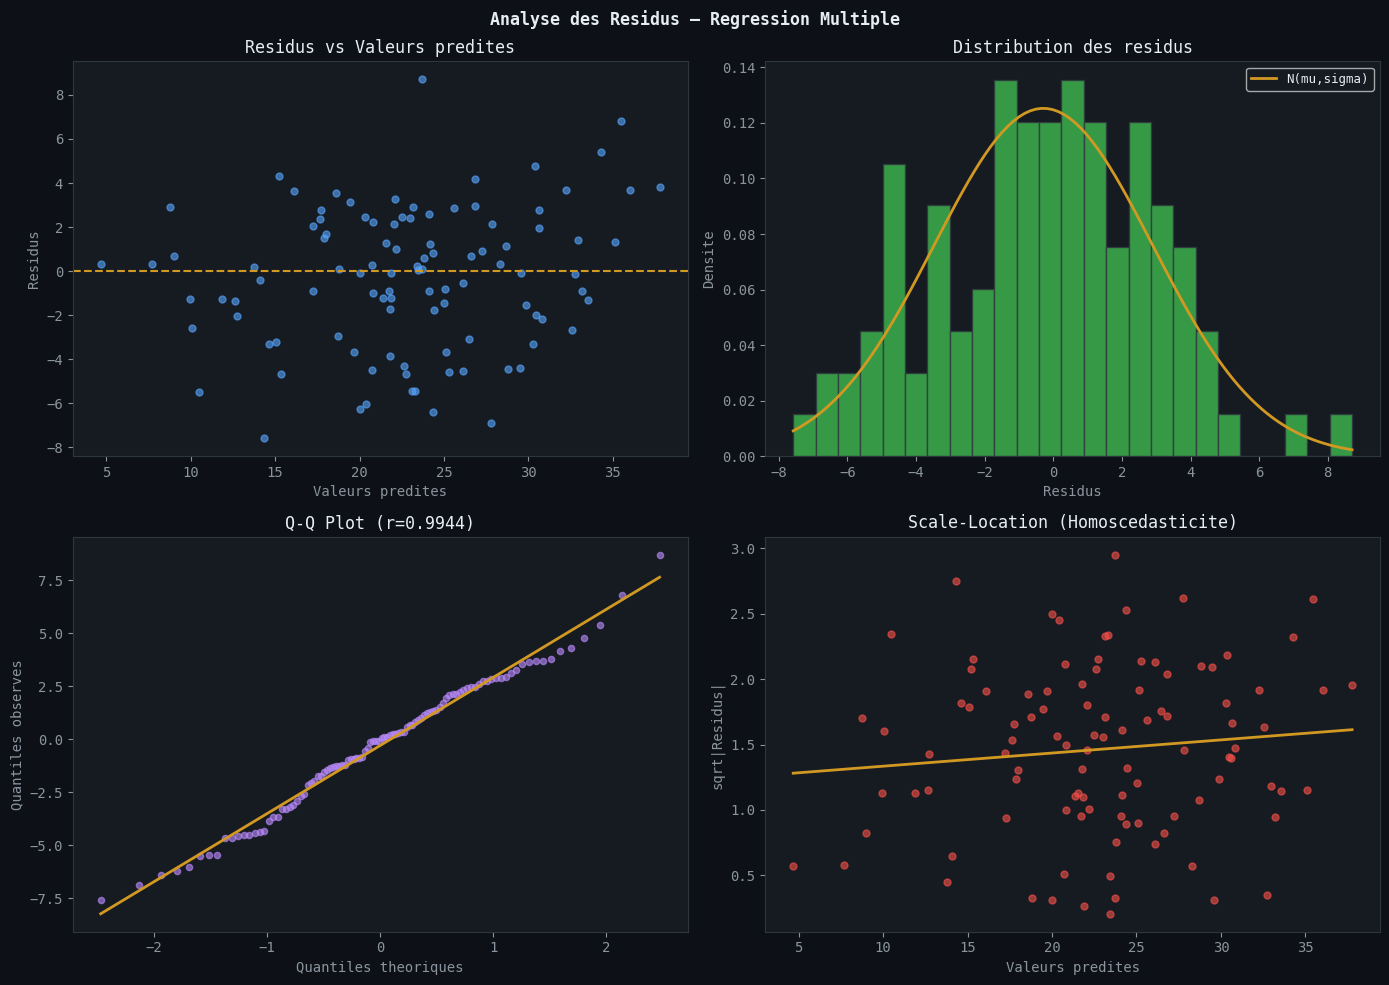

Residus sauvegardes


In [28]:
residuals = y_test - y_pred_multi

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.patch.set_facecolor(DARK)
fig.suptitle("Analyse des Residus — Regression Multiple", color=TEXT, fontsize=12, fontweight="bold")

ax = axes[0,0]
ax.set_facecolor(CARD)
ax.scatter(y_pred_multi, residuals, color=BLUE, alpha=0.6, s=25)
ax.axhline(0, color=ORNG, linewidth=1.5, linestyle="--")
ax.set_title("Residus vs Valeurs predites", color=TEXT)
ax.set_xlabel("Valeurs predites", color=DIM)
ax.set_ylabel("Residus", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[0,1]
ax.set_facecolor(CARD)
mu, sigma = residuals.mean(), residuals.std()
ax.hist(residuals, bins=25, color=GREEN, alpha=0.8, edgecolor=BORD, density=True)
xn = np.linspace(residuals.min(), residuals.max(), 100)
ax.plot(xn, stats.norm.pdf(xn, mu, sigma), color=ORNG, linewidth=2, label="N(mu,sigma)")
ax.set_title("Distribution des residus", color=TEXT)
ax.set_xlabel("Residus", color=DIM)
ax.set_ylabel("Densite", color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[1,0]
ax.set_facecolor(CARD)
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist="norm")
ax.scatter(osm, osr, color=PURP, alpha=0.6, s=20)
ax.plot(osm, slope*np.array(osm)+intercept, color=ORNG, linewidth=2)
ax.set_title(f"Q-Q Plot (r={r:.4f})", color=TEXT)
ax.set_xlabel("Quantiles theoriques", color=DIM)
ax.set_ylabel("Quantiles observes", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

ax = axes[1,1]
ax.set_facecolor(CARD)
sqrt_res = np.sqrt(np.abs(residuals))
ax.scatter(y_pred_multi, sqrt_res, color=RED, alpha=0.6, s=25)
z2 = np.polyfit(y_pred_multi, sqrt_res, 1)
xs = np.sort(y_pred_multi)
ax.plot(xs, np.poly1d(z2)(xs), color=ORNG, linewidth=2)
ax.set_title("Scale-Location (Homoscedasticite)", color=TEXT)
ax.set_xlabel("Valeurs predites", color=DIM)
ax.set_ylabel("sqrt|Residus|", color=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)

stat_sw, p_sw = stats.shapiro(residuals.values[:50])
print(f"Shapiro-Wilk : stat={stat_sw:.4f}, p={p_sw:.4f}")
print(f"Residus {"normaux" if p_sw > 0.05 else "non normaux"}")

plt.tight_layout()
plt.savefig("../images/05_residuals.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show()
print("Residus sauvegardes")

## 7. OLS Statsmodels

In [30]:

X_ols = sm.add_constant(X_train_sc)
ols_model = sm.OLS(y_train, X_ols).fit()

print(ols_model.summary())

ols_df = pd.DataFrame({
    "Feature": ["const"] + list(feature_names),
    "Coef": ols_model.params.values,
    "p-value": ols_model.pvalues.values,
    "Sig": [
        "***" if p < 0.001 else
        "**" if p < 0.01 else
        "*" if p < 0.05 else ""
        for p in ols_model.pvalues.values
    ]
})

print("\n=== VARIABLES SIGNIFICATIVES (p < 0.05) ===")

print(
    ols_df[ols_df["p-value"] < 0.05][
        ["Feature", "Coef", "p-value", "Sig"]
    ].to_string(index=False)
)


                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.875
Method:                 Least Squares   F-statistic:                     217.4
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          1.51e-169
Time:                        01:51:07   Log-Likelihood:                -1025.3
No. Observations:                 404   AIC:                             2079.
Df Residuals:                     390   BIC:                             2135.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         21.4933      0.155    138.625      0.0

## 8. Ridge & Lasso

In [32]:
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.1, max_iter=10000)
ridge.fit(X_train_sc, y_train)
lasso.fit(X_train_sc, y_train)
y_pred_ridge = ridge.predict(X_test_sc)
y_pred_lasso = lasso.predict(X_test_sc)

results = {
    "Lineaire Simple":   (r2_simple, rmse_simple, mae_simple, mape_simple),
    "Lineaire Multiple": (r2_multi,  rmse_multi,  mae_multi,  mape_multi),
    "Ridge (a=1.0)":     (r2_score(y_test, y_pred_ridge),
                          np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
                          mean_absolute_error(y_test, y_pred_ridge),
                          np.mean(np.abs((y_test-y_pred_ridge)/y_test))*100),
    "Lasso (a=0.1)":     (r2_score(y_test, y_pred_lasso),
                          np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
                          mean_absolute_error(y_test, y_pred_lasso),
                          np.mean(np.abs((y_test-y_pred_lasso)/y_test))*100),
}

comp_df = pd.DataFrame(results, index=["R2","RMSE","MAE","MAPE(%)"] ).T.round(4)
print("=== COMPARAISON DES MODELES ===")
print(comp_df)

lasso_coef = pd.Series(lasso.coef_, index=feature_names)
print(f"Lasso — Features eliminees : {list(lasso_coef[lasso_coef==0].index)}")
print(f"Lasso — Features conservees : {list(lasso_coef[lasso_coef!=0].index)}")

=== COMPARAISON DES MODELES ===
                       R2    RMSE     MAE  MAPE(%)
Lineaire Simple    0.0503  7.8205  6.1904  37.6956
Lineaire Multiple  0.8427  3.1825  2.5472  14.0700
Ridge (a=1.0)      0.8425  3.1849  2.5478  14.0732
Lasso (a=0.1)      0.8363  3.2470  2.5983  14.4519
Lasso — Features eliminees : []
Lasso — Features conservees : ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


## 9. Cross-Validation 10-Fold

Lineaire     | R2 CV mean=0.8602 +/- 0.0276
Ridge        | R2 CV mean=0.8602 +/- 0.0273
Lasso        | R2 CV mean=0.8580 +/- 0.0245


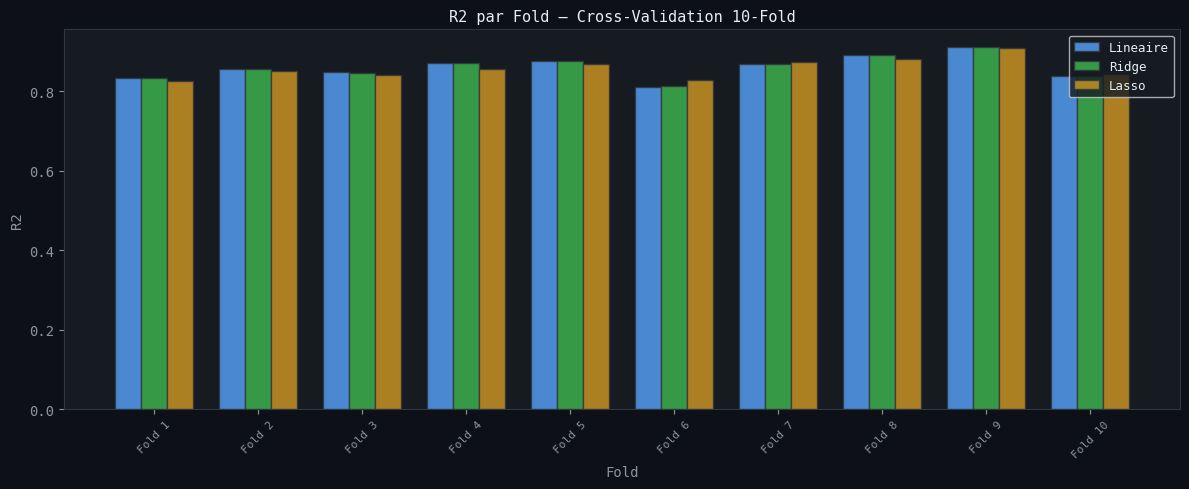

Cross-validation sauvegardee


In [33]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
X_sc_full = scaler.fit_transform(X)

cv_results = {}
for name, model in [("Lineaire", LinearRegression()),
                     ("Ridge",    Ridge(alpha=1.0)),
                     ("Lasso",    Lasso(alpha=0.1, max_iter=10000))]:
    scores = cross_val_score(model, X_sc_full, y, cv=kf, scoring="r2")
    cv_results[name] = scores
    print(f"{name:12s} | R2 CV mean={scores.mean():.4f} +/- {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)
x_pos = np.arange(10)
width = 0.25
for i, (name, scores) in enumerate(cv_results.items()):
    ax.bar(x_pos + i*width, scores, width, label=name,
           color=[BLUE,GREEN,ORNG][i], alpha=0.8, edgecolor=BORD)
ax.set_title("R2 par Fold — Cross-Validation 10-Fold", color=TEXT, fontsize=11)
ax.set_xlabel("Fold", color=DIM)
ax.set_ylabel("R2", color=DIM)
ax.set_xticks(x_pos + width)
ax.set_xticklabels([f"Fold {i+1}" for i in range(10)], rotation=45, color=DIM, fontsize=8)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)
plt.tight_layout()
plt.savefig("../images/06_cross_validation.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show()
print("Cross-validation sauvegardee")

## 10. Importance des Features

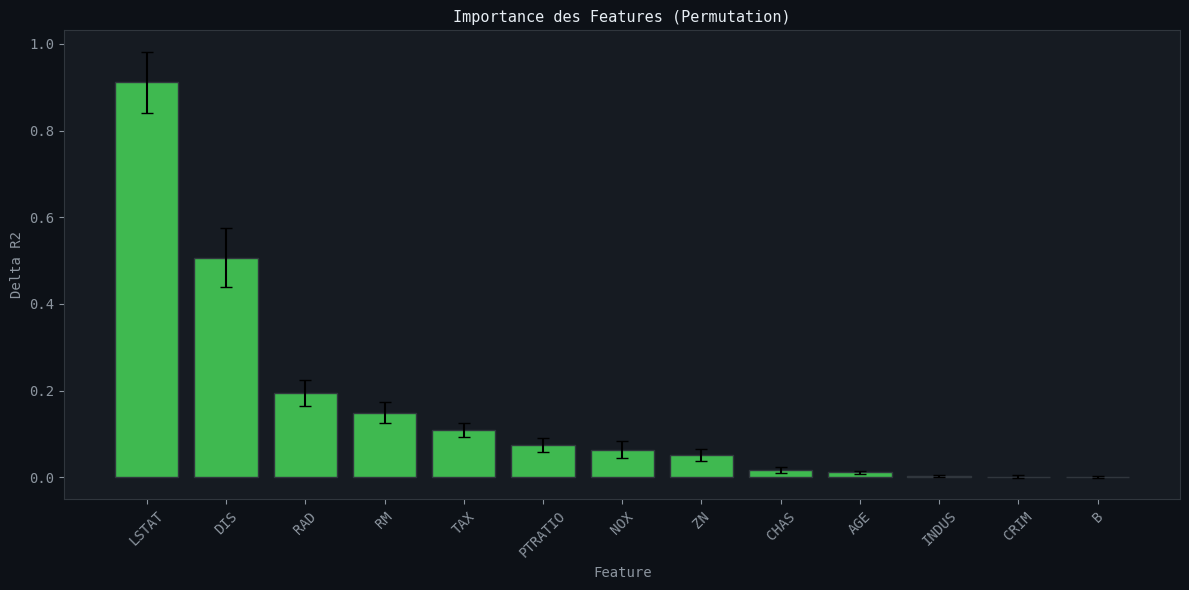

Top 5 features:
  LSTAT: 0.9119 — % population bas revenus
  DIS: 0.5063 — Distance aux centres emploi
  RAD: 0.1949 — Indice acces autoroutes
  RM: 0.1488 — Nombre moyen de pieces
  TAX: 0.1092 — Taxe fonciere pour 10 000


In [34]:
perm_imp = permutation_importance(lr_multi, X_test_sc, y_test, n_repeats=30, random_state=42)
imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": perm_imp.importances_mean,
    "Std": perm_imp.importances_std
}).sort_values("Importance", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)
clrs_i = [GREEN if v > 0 else RED for v in imp_df["Importance"]]
ax.bar(imp_df["Feature"], imp_df["Importance"], color=clrs_i,
       yerr=imp_df["Std"], capsize=4, edgecolor=BORD, error_kw={"color": DIM})
ax.set_title("Importance des Features (Permutation)", color=TEXT, fontsize=11)
ax.set_xlabel("Feature", color=DIM)
ax.set_ylabel("Delta R2", color=DIM)
ax.tick_params(axis="x", rotation=45, colors=DIM)
for spine in ax.spines.values(): spine.set_color(BORD)
plt.tight_layout()
plt.savefig("../images/07_feature_importance.png", dpi=120, bbox_inches="tight", facecolor=DARK)
plt.show()
print("Top 5 features:")
for _, row in imp_df.head(5).iterrows():
    print(f"  {row["Feature"]}: {row["Importance"]:.4f} — {descriptions.get(row["Feature"],"")}")

## 11. Dashboard Final

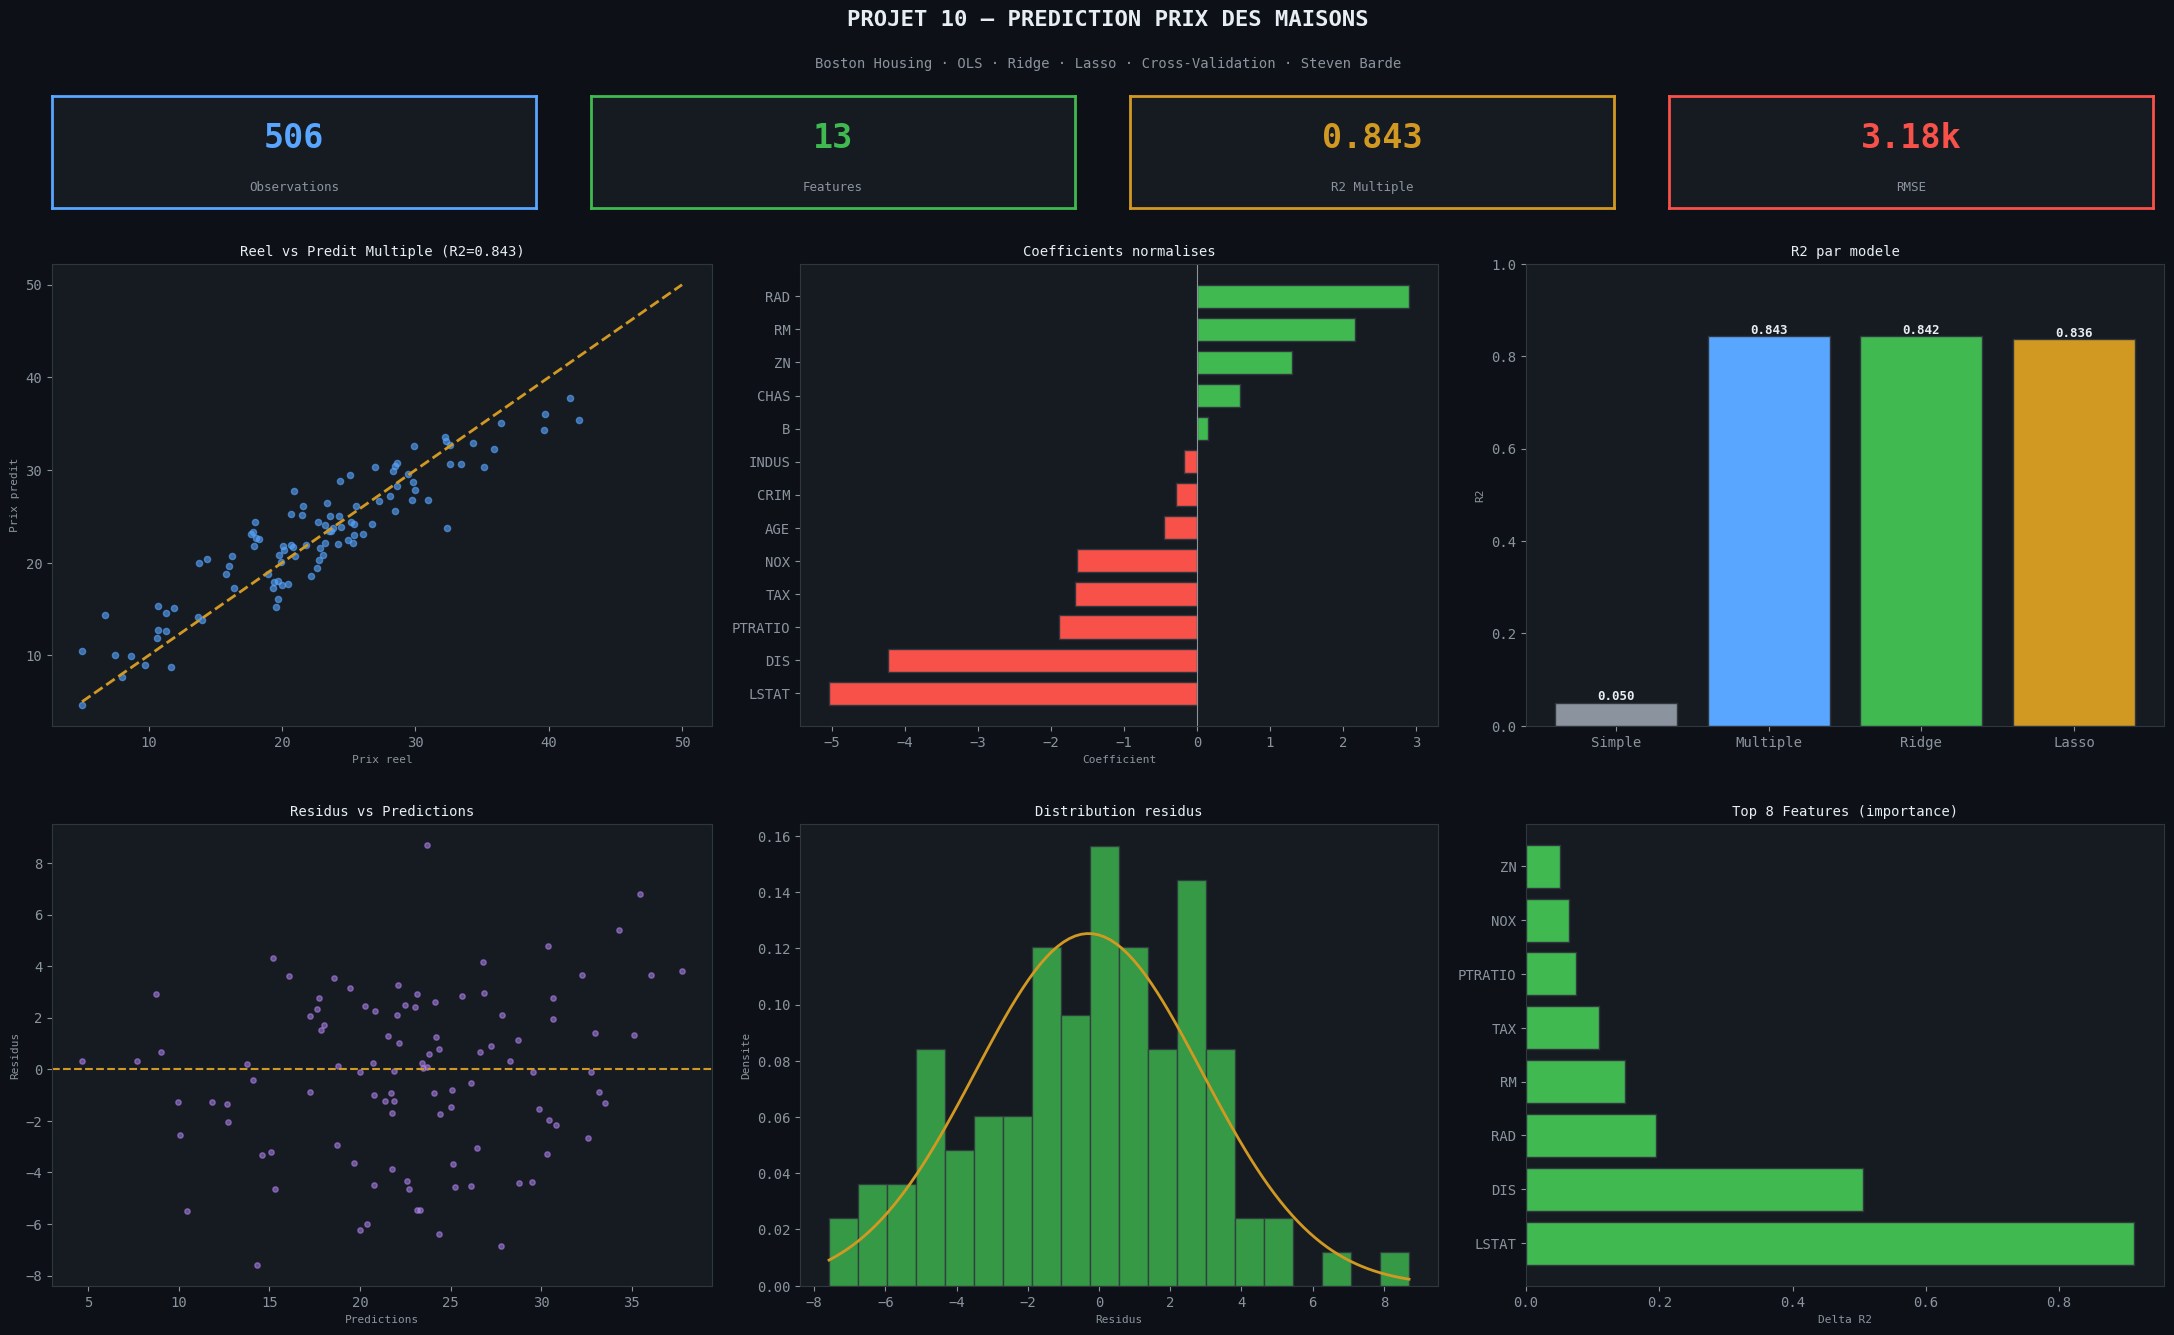

Dashboard sauvegarde : ../images/00_dashboard_regression.png


In [35]:
fig = plt.figure(figsize=(22, 14))
fig.patch.set_facecolor(DARK)
fig.text(0.5, 0.97, "PROJET 10 — PREDICTION PRIX DES MAISONS",
         ha="center", color=TEXT, fontsize=16, fontweight="bold")
fig.text(0.5, 0.94, "Boston Housing · OLS · Ridge · Lasso · Cross-Validation · Steven Barde",
         ha="center", color=DIM, fontsize=10)

kpis = [("506","Observations",BLUE),("13","Features",GREEN),
        (f"{r2_multi:.3f}","R2 Multiple",ORNG),(f"{rmse_multi:.2f}k","RMSE",RED)]
for i,(val,lbl,clr) in enumerate(kpis):
    ax_k = fig.add_axes([0.02+i*0.245, 0.84, 0.22, 0.08])
    ax_k.set_facecolor(CARD)
    for spine in ax_k.spines.values(): spine.set_color(clr); spine.set_linewidth(2)
    ax_k.set_xticks([]); ax_k.set_yticks([])
    ax_k.text(0.5,0.62,val,ha="center",va="center",color=clr,fontsize=24,fontweight="bold",transform=ax_k.transAxes)
    ax_k.text(0.5,0.18,lbl,ha="center",va="center",color=DIM,fontsize=9,transform=ax_k.transAxes)

ax1 = fig.add_axes([0.02, 0.47, 0.30, 0.33])
ax1.set_facecolor(CARD)
ax1.scatter(y_test, y_pred_multi, color=BLUE, alpha=0.6, s=20)
ax1.plot([5,50],[5,50], color=ORNG, linewidth=2, linestyle="--")
ax1.set_title(f"Reel vs Predit Multiple (R2={r2_multi:.3f})", color=TEXT, fontsize=10)
ax1.set_xlabel("Prix reel", color=DIM, fontsize=8)
ax1.set_ylabel("Prix predit", color=DIM, fontsize=8)
for spine in ax1.spines.values(): spine.set_color(BORD)

ax2 = fig.add_axes([0.36, 0.47, 0.29, 0.33])
ax2.set_facecolor(CARD)
cs2 = coef_df.sort_values("Coefficient")
clrs2 = [RED if v < 0 else GREEN for v in cs2["Coefficient"]]
ax2.barh(cs2["Feature"], cs2["Coefficient"], color=clrs2, edgecolor=BORD, height=0.7)
ax2.axvline(0, color=DIM, linewidth=0.8)
ax2.set_title("Coefficients normalises", color=TEXT, fontsize=10)
ax2.set_xlabel("Coefficient", color=DIM, fontsize=8)
for spine in ax2.spines.values(): spine.set_color(BORD)

ax3 = fig.add_axes([0.69, 0.47, 0.29, 0.33])
ax3.set_facecolor(CARD)
mnames = ["Simple","Multiple","Ridge","Lasso"]
r2vals = [r2_simple, r2_multi,
          r2_score(y_test,y_pred_ridge), r2_score(y_test,y_pred_lasso)]
bars3 = ax3.bar(mnames, r2vals, color=[DIM,BLUE,GREEN,ORNG], edgecolor=BORD)
for bar, v in zip(bars3, r2vals):
    ax3.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005, f"{v:.3f}",
             ha="center", color=TEXT, fontsize=9, fontweight="bold")
ax3.set_title("R2 par modele", color=TEXT, fontsize=10)
ax3.set_ylabel("R2", color=DIM, fontsize=8)
ax3.set_ylim(0,1)
for spine in ax3.spines.values(): spine.set_color(BORD)

ax4 = fig.add_axes([0.02, 0.07, 0.30, 0.33])
ax4.set_facecolor(CARD)
ax4.scatter(y_pred_multi, residuals, color=PURP, alpha=0.5, s=15)
ax4.axhline(0, color=ORNG, linewidth=1.5, linestyle="--")
ax4.set_title("Residus vs Predictions", color=TEXT, fontsize=10)
ax4.set_xlabel("Predictions", color=DIM, fontsize=8)
ax4.set_ylabel("Residus", color=DIM, fontsize=8)
for spine in ax4.spines.values(): spine.set_color(BORD)

ax5 = fig.add_axes([0.36, 0.07, 0.29, 0.33])
ax5.set_facecolor(CARD)
ax5.hist(residuals, bins=20, color=GREEN, alpha=0.8, edgecolor=BORD, density=True)
ax5.plot(xn, stats.norm.pdf(xn, mu, sigma), color=ORNG, linewidth=2)
ax5.set_title("Distribution residus", color=TEXT, fontsize=10)
ax5.set_xlabel("Residus", color=DIM, fontsize=8)
ax5.set_ylabel("Densite", color=DIM, fontsize=8)
for spine in ax5.spines.values(): spine.set_color(BORD)

ax6 = fig.add_axes([0.69, 0.07, 0.29, 0.33])
ax6.set_facecolor(CARD)
top8 = imp_df.head(8)
clrs6 = [GREEN if v > 0 else RED for v in top8["Importance"]]
ax6.barh(top8["Feature"], top8["Importance"], color=clrs6, edgecolor=BORD)
ax6.set_title("Top 8 Features (importance)", color=TEXT, fontsize=10)
ax6.set_xlabel("Delta R2", color=DIM, fontsize=8)
for spine in ax6.spines.values(): spine.set_color(BORD)

plt.savefig("../images/00_dashboard_regression.png", dpi=130, bbox_inches="tight", facecolor=DARK)
plt.show()
print("Dashboard sauvegarde : ../images/00_dashboard_regression.png")

In [36]:
print("=" * 55)
print("    SYNTHESE — PROJET 10 REGRESSION LINEAIRE")
print("=" * 55)
print(f"Dataset : Boston Housing ({n} obs, 13 features)")
print(f"Split   : 80% train / 20% test")
print()
for mname, (r2,rmse,mae,mape) in results.items():
    print(f"  {mname:22s} | R2={r2:.3f}  RMSE={rmse:.2f}  MAE={mae:.2f}")
print()
print("Top 3 features:")
for _, row in imp_df.head(3).iterrows():
    print(f"  {row["Feature"]}: {descriptions.get(row["Feature"],"")}")
print("=" * 55)

    SYNTHESE — PROJET 10 REGRESSION LINEAIRE
Dataset : Boston Housing (506 obs, 13 features)
Split   : 80% train / 20% test

  Lineaire Simple        | R2=0.050  RMSE=7.82  MAE=6.19
  Lineaire Multiple      | R2=0.843  RMSE=3.18  MAE=2.55
  Ridge (a=1.0)          | R2=0.842  RMSE=3.18  MAE=2.55
  Lasso (a=0.1)          | R2=0.836  RMSE=3.25  MAE=2.60

Top 3 features:
  LSTAT: % population bas revenus
  DIS: Distance aux centres emploi
  RAD: Indice acces autoroutes
